# Fig. 6 · L4 动力学与输运（液态，0.0309 Å⁻³）

**主张**：扩散系数必须与拟合窗口一起报，且只在已证明处于平衡的轨迹上算。三个同密度温度点构成 Arrhenius 序列。

- **a** 各模型在 950 / 1200 / 3000 K 的 Δlog₁₀D（9 个模型；灰带 = floor 0.05 decade）。
- **b** 1200 K 全物种 MSD（AIMD vs 四个代表模型）。
- **c** Arrhenius：D(全物种) vs 1000/T。

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as NotebookImage, display
sys.path.insert(0, str(Path.cwd()))
from style import *

In [2]:
# ---------------- 字体设置 / fonts（唯一定义字号的地方） ----------------
FS = use_paper_fonts()          # PAPER_FONTS lives in style.py
FS_TITLE, FS_LABEL, FS_TICK   = FS['title'], FS['label'], FS['tick']
FS_LEGEND, FS_ANNOT, FS_PANEL = FS['legend'], FS['annot'], FS['panel']
FS_CBLABEL, FS_CBTICK         = FS['cbar_label'], FS['cbar_tick']

In [3]:
NAME = "fig6_L4"
OUT = FIG_ROOT / "panels" / NAME
PREVIEW_SCALE = 0.25          # notebook 内预览缩放；不影响导出
LEFT, RIGHT, WS = 0.135, 0.985, 0.42    # copied verbatim by every 3-column figure
CH, G, BM, TM = 1.45, 0.62, 0.36, 0.24  # row height, row gap, bottom/top margin (in)
ROWS = 1
LETTERS = "abc"

def make_layout():
    H = BM + ROWS * CH + (ROWS - 1) * G + TM
    fig = plt.figure(figsize=(W2, H))
    gs = fig.add_gridspec(ROWS, 3, left=LEFT, right=RIGHT, bottom=BM / H, top=1 - TM / H,
                          wspace=WS, hspace=G / CH)
    slots = {}
    for i, letter in enumerate(LETTERS):
        r, c = divmod(i, 3)
        slots[letter] = gs[r, c]
    return fig, Slots(slots)

def panel_run(letter, draw):
    fig, slots = make_layout()
    draw(fig, slots[letter])
    group = {"axes": list(fig.axes), "texts": list(fig.texts)}
    boxes = save_matched_panels(fig, {letter: group}, OUT); plt.close(fig)
    display(NotebookImage(filename=str(OUT / f"{letter}.png"), width=int(boxes[letter].width * 600 * PREVIEW_SCALE)))

In [4]:
def model_rows(ax, show_labels):
    """Shared y axis for the nine-model summary panels: universal on top, specialised below."""
    y = {k: i for i, k in enumerate(SHOWCASE)}
    ax.set_ylim(len(SHOWCASE) - 0.4, -0.6)
    ax.set_yticks(range(len(SHOWCASE)))
    ax.set_yticklabels([lab(k) for k in SHOWCASE] if show_labels else [])
    ax.axhline(len(UNIVERSAL) - 0.5, color="#BBBBBB", lw=0.4, ls=(0, (2, 2)))
    ax.tick_params(axis="y", length=0)
    return y

def contaminated(model):
    from mlipeval.ranking import contaminated_metric_ids
    return set(contaminated_metric_ids([model]))

In [5]:
TEMPS = {"canon_liquid_950K": 950, "canon_liquid_1200K": 1200, "canon_liquid_3000K": 3000}
L4 = {k: {s: results(k, f"L4_{s}__lammps.json") for s in TEMPS} for k in SHOWCASE}

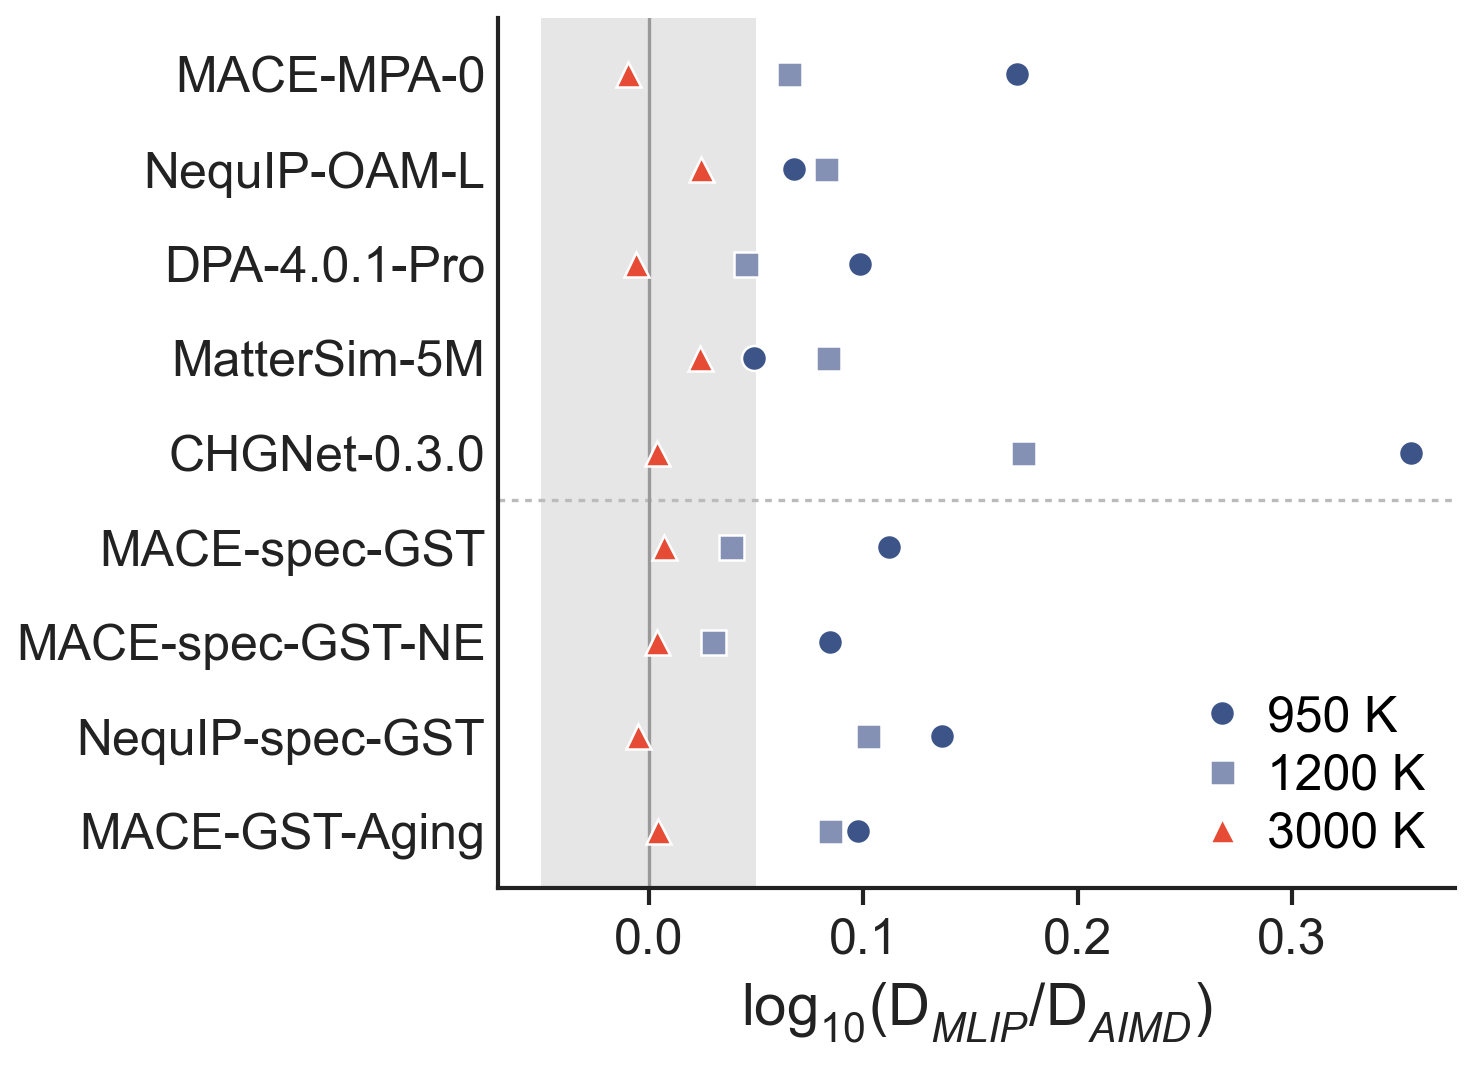

In [6]:
# ---------------- 本面板配色 ----------------
Ca_T = {950: "#3C5488", 1200: "#8491B4", 3000: "#E64B35"}
Ca_MARK = {950: "o", 1200: "s", 3000: "^"}
# --------------------------------------------
def draw_a(fig, spec):
    ax = fig.add_subplot(spec)
    y = model_rows(ax, True)
    ax.axvspan(-0.05, 0.05, color="#E6E6E6", lw=0)
    ax.axvline(0, color="#999999", lw=0.4)
    for k in SHOWCASE:
        for s, T in TEMPS.items():
            r = L4[k][s].get(f"L4.diffusion.all.delta_log10D@{s}")
            if r is None: continue
            ex = r["extra"]; v = np.log10(ex["model_D_cm2_per_s"] / ex["reference_D_cm2_per_s"])
            ax.plot(v, y[k], Ca_MARK[T], color=Ca_T[T], ms=3, mec="white", mew=0.3, label=f"{T} K" if k == SHOWCASE[0] else None)
    ax.set_xlabel("log$_{10}$(D$_{MLIP}$/D$_{AIMD}$)")
    ax.legend(loc="lower right", handletextpad=0.1)
    return ax
panel_run("a", draw_a)

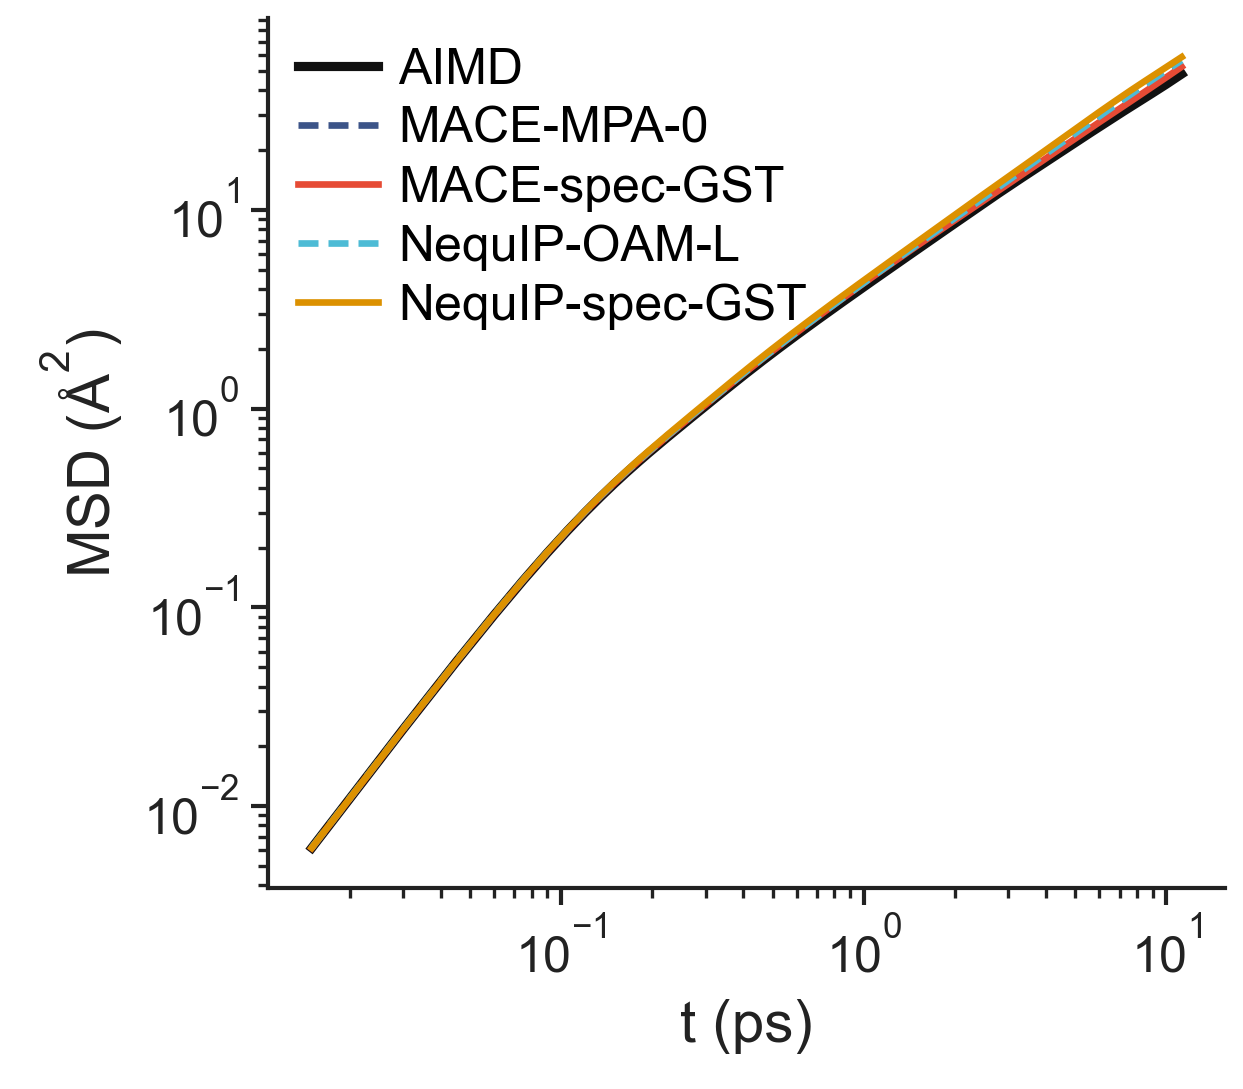

In [7]:
# ---------------- 本面板配色 ----------------
Cb_REF = "#111111"
# --------------------------------------------
def draw_b(fig, spec):
    ax = fig.add_subplot(spec)
    z0 = npz("mace_mpa0", "l4_canon_liquid_1200K.npz")
    ax.loglog(z0["time_ref"][1:] / 1000, z0["msd_ref_all"][1:], color=Cb_REF, lw=1.1, label="AIMD")
    for k in FOCUS:
        z = npz(k, "l4_canon_liquid_1200K.npz")
        ls = "-" if MODELS[k][3] == "specialised" else (0, (3, 1.5))
        ax.loglog(z["time_model"][1:] / 1000, z["msd_model_all"][1:], color=col(k), lw=0.8, ls=ls, label=lab(k))
    ax.set_xlabel("t (ps)"); ax.set_ylabel("MSD (Å$^2$)")
    ax.legend(loc="upper left")
    return ax
panel_run("b", draw_b)

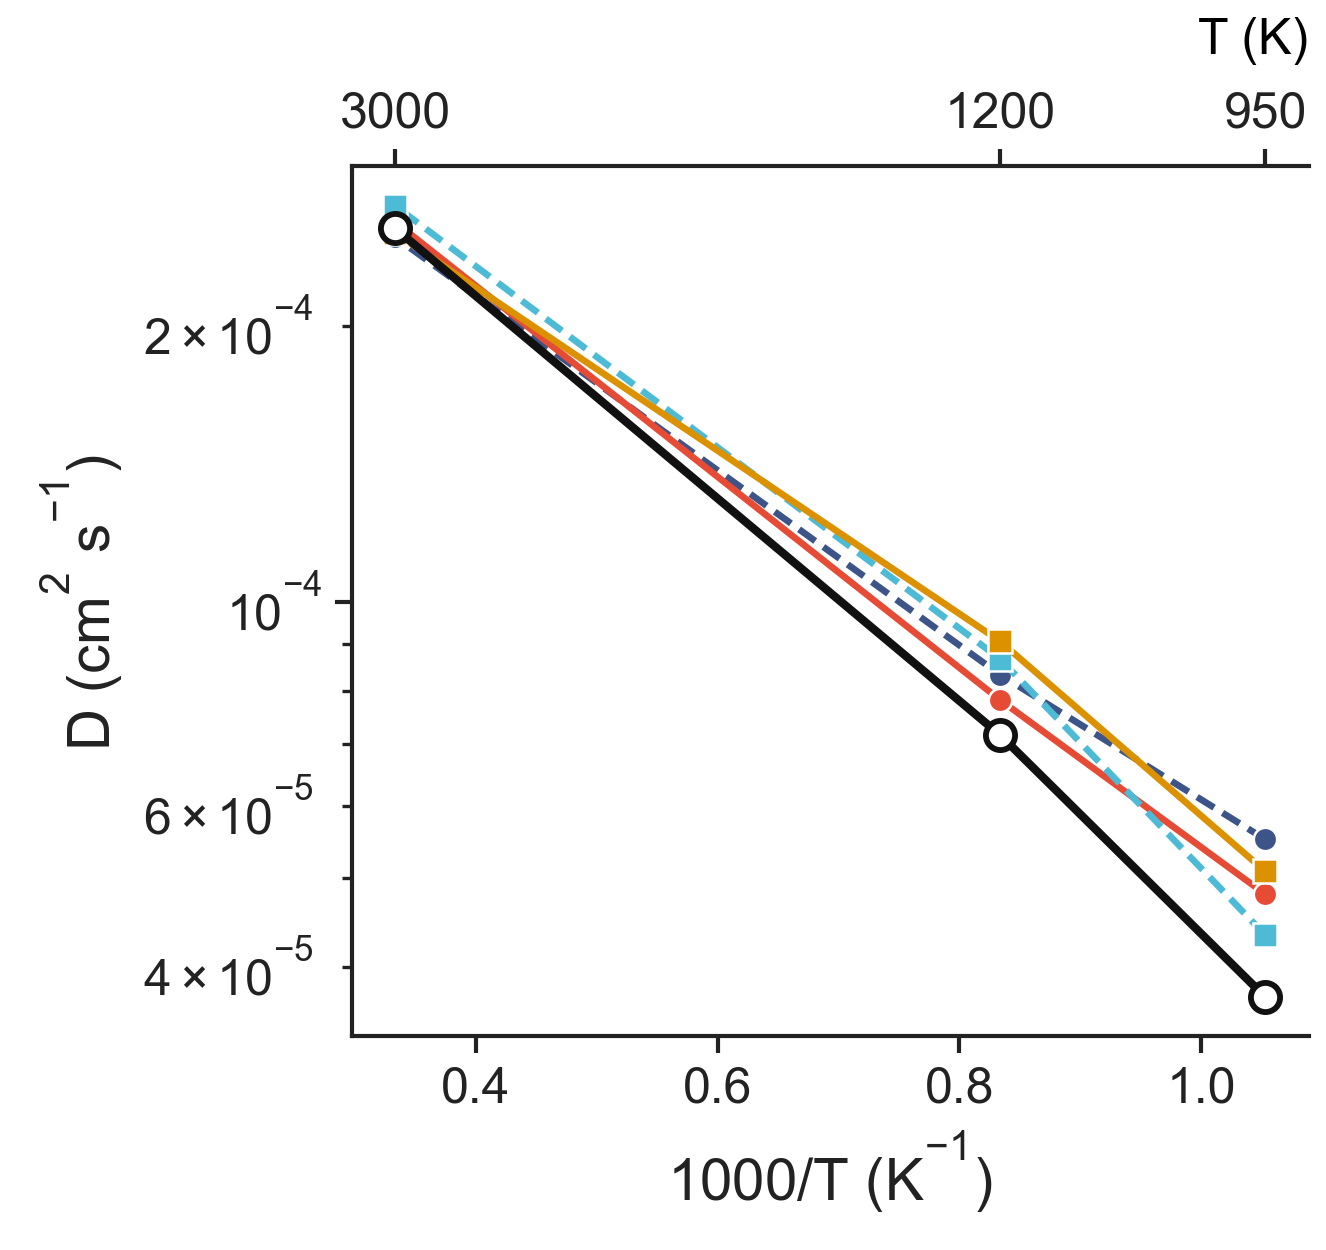

In [8]:
# ---------------- 本面板配色 ----------------
Cc_REF = "#111111"
# --------------------------------------------
def draw_c(fig, spec):
    ax = fig.add_subplot(spec)
    x = np.array([1000 / T for T in TEMPS.values()])
    ref = [L4["mace_mpa0"][s][f"L4.diffusion.all.delta_log10D@{s}"]["extra"]["reference_D_cm2_per_s"] for s in TEMPS]
    ax.semilogy(x, ref, "o-", color=Cc_REF, lw=1.0, ms=3.5, mfc="white", mew=0.7, label="AIMD", zorder=3)
    for k in FOCUS:
        d = [L4[k][s][f"L4.diffusion.all.delta_log10D@{s}"]["extra"]["model_D_cm2_per_s"] for s in TEMPS]
        ls = "-" if MODELS[k][3] == "specialised" else (0, (3, 1.5))
        ax.semilogy(x, d, marker=mkr(k), color=col(k), lw=0.8, ls=ls, ms=2.8, mec="white", mew=0.3)
    ax.set_xlabel("1000/T (K$^{-1}$)"); ax.set_ylabel("D (cm$^2$ s$^{-1}$)")
    ax.secondary_xaxis("top", functions=(lambda u: 1000 / np.maximum(u, 1e-6), lambda T: 1000 / np.maximum(T, 1e-6))).set_xticks([3000, 1200, 950])
    ax.text(1.0, 1.13, "T (K)", transform=ax.transAxes, ha="right", fontsize=FS_TICK)
    return ax
panel_run("c", draw_c)

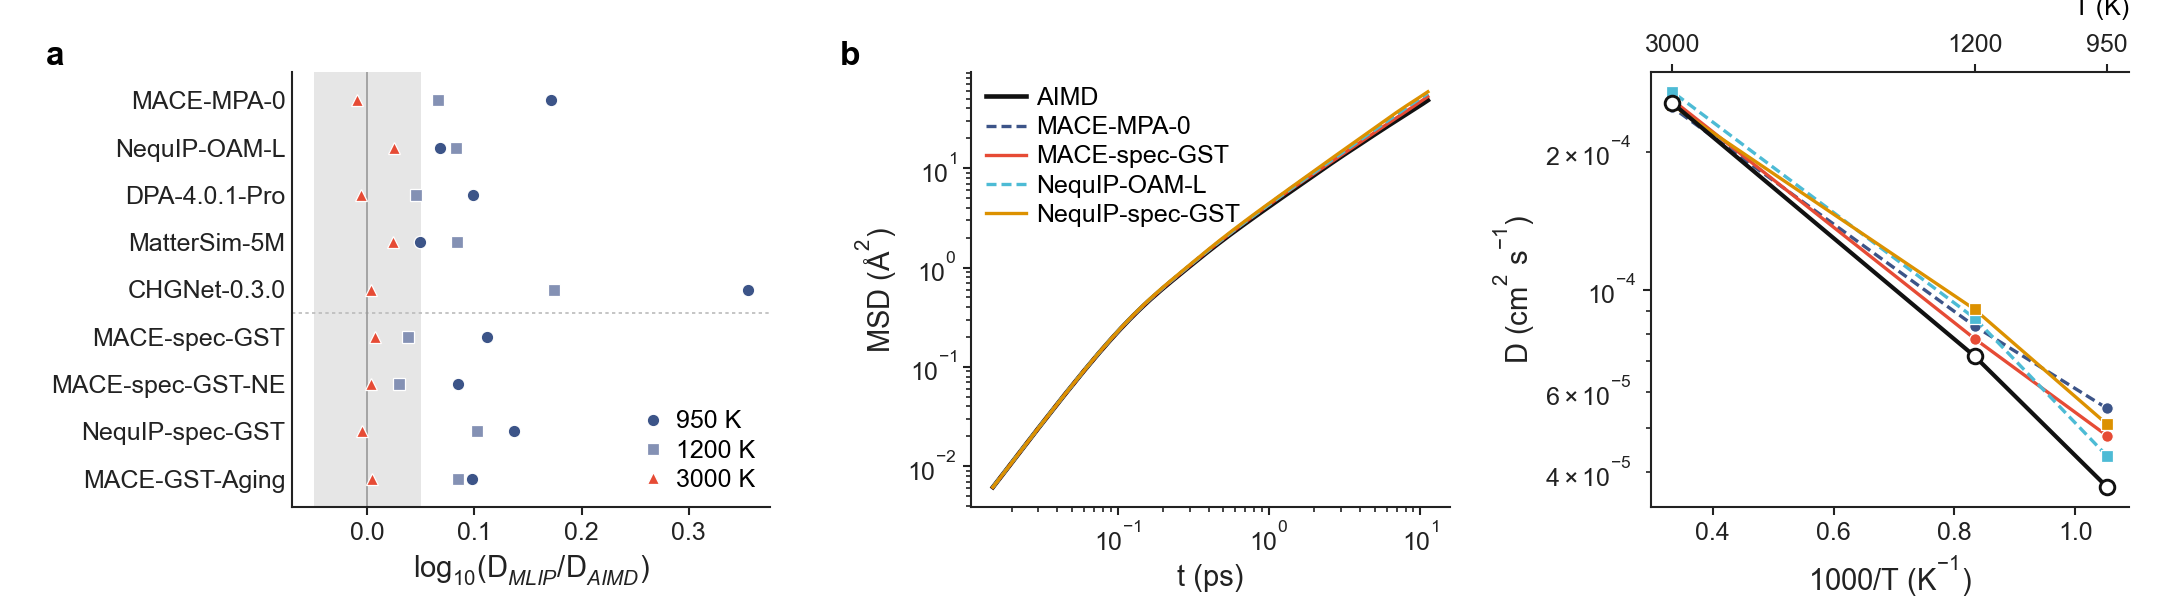

In [9]:
fig, slots = make_layout()
DRAW = {l: globals()[f"draw_{l}"] for l in LETTERS}
main_axes = {}
for l in LETTERS:
    n0 = len(fig.axes)
    ax = DRAW[l](fig, slots[l])
    main_axes[l] = ax
for l in LETTERS:
    mark(fig, main_axes[l], l, FS_PANEL)
png = export(fig, "fig6_L4")
groups = {}
plt.close(fig)
display(NotebookImage(filename=str(png), width=900))